In [9]:
import tensorflow as tf
import random
from tensorflow import keras
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report, confusion_matrix
from matplotlib import rc
import matplotlib.pyplot as plt
import seaborn as sns
import os
import joblib

print(tf.__version__)

rc('font', family='AppleGothic')
plt.rcParams['axes.unicode_minus'] = False

seed = 42
random.seed(seed)
tf.random.set_seed(seed)
np.random.seed(seed)

2.11.0


### 트레인셋과 테스트셋에서 target 열의 클래스 비율이 유지되도록 8:2 split (함수)

In [10]:
def split_data(data):
    # feature 컬럼만 가져오기
    X = data.drop(['Target','SurgeryID', 'PatientID', 'SurgeryDate', 'BodyPart', 'SideEffect'], axis=1)

    # target 컬럼만 가져오기
    y = data['Target']
    
    # train/test 데이터 분리 (8:2)
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)

    return X_train, X_test, y_train, y_test


### Data Scaling z-score (함수)

In [11]:
def data_scaling(X_train, X_test):
   X_columns = X_train.columns
   stds = StandardScaler()
   stds.fit(X_train)
   X_train = stds.transform(X_train)
   X_test = stds.transform(X_test)

   X_train = pd.DataFrame(X_train, columns=X_columns)
   X_test = pd.DataFrame(X_test, columns=X_columns)

   return X_train, X_test


### Random Forest 모델 학습 및 성능 평가, 시각화 (함수)

In [12]:
def conf_matrix(y_test, y_pred, aftereffect, save_dir):
    # plt.figure(figsize = (7, 7))
    # y_test와 results의 numpy 행렬에서 최고 차수(-1)를 기준으로 비교하여 최고값을 선정.
    # cm = confusion_matrix(np.argmax(y_test, axis = -1), np.argmax(results, axis = -1))
    y_test = np.argmax(y_test, axis=-1).tolist()
    y_pred = np.argmax(y_pred, axis=-1).tolist()
    
    # 혼동행렬 생성
    cm = confusion_matrix(y_test, y_pred)

    # sklearn의 데이터를 이용하여 heatmap을 시각화해주는 seaborn의 패키지
    sns.heatmap(cm, annot = True, fmt = 'd',cmap = 'Blues')

    plt.title(aftereffect)
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')

    os.makedirs(save_dir, exist_ok=True)
    plt.savefig(save_dir+aftereffect+'_'+'CMatrix.png')
    plt.show()

    print('\n', classification_report(y_test, y_pred))


In [13]:
KEY_columns = ['고객번호', '수술일자', '수술의', '부위명']
EMR_columns = ['기수', '수술소요시간', '나이', '흡연', '음주', '체수분', '단백질', '체중', '지방량', '체지방', '체지방량', '골격근지방골격근량', '비만진단BMI', '비만진단체지방률', '비만진단복부지방률', '기초대사량']
SCAN_columns = ['허벅지부분체적', '종아리우부분체적', '상복부최대둘레', '엉덩이둘레', '배꼽점둘레', '종아리부분체적', '가슴부분체적', '하복부최대둘레높이의단면적', '상복부최대둘레높이', '종아리둘레', '복부최대둘레높이', '허벅지신장비율ThightoHeightRatio', '총표면적', '복부부분체적', '명치부분체적', '허리둘레', '복부최대둘레', '하복부최대둘레', '허리엉덩이비율WaisttoHipRatio', '하복부둘레', '상복부최대둘레높이의단면적', '허리가슴비율WaisttoChestRatio', '하복부부분체적', '상복부부분체적', '골반부분체적', '종아리좌부분체적', '체질량지수', '팔둘레', '체적', '팔좌부분체적', '메쉬신장', '허벅지둘레', '허리신장비율WaisttoHeightRatio', '복부최대둘레높이의단면적', '팔우부분체적', '무릎둘레오른쪽', '가슴둘레']
ULTRA_columns = ['초음파사이즈1', '초음파사이즈2']
TARGET_columns = ['target']
KPI_1_0_columns = ['totalStrokeCount', 'totalStrokeVelocity', 'totalStrokeDepth', 'upDownTotalStrokeCount', 'upDownTotalStrokeVelocity', 'upDownTotalStrokeDepth', 'leftRightTotalStrokeCount', 'leftRightTotalStrokeVelocity', 'leftRightTotalStrokeDepth', 'quadrant1TotalStrokeCount', 'quadrant1TotalStrokeVelocity', 'quadrant1TotalStrokeDepth', 'quadrant2TotalStrokeCount', 'quadrant2TotalStrokeVelocity', 'quadrant2TotalStrokeDepth', 'quadrant3TotalStrokeCount', 'quadrant3TotalStrokeVelocity', 'quadrant3TotalStrokeDepth', 'quadrant4TotalStrokeCount', 'quadrant4TotalStrokeVelocity', 'quadrant4TotalStrokeDepth']


In [14]:
data_path = '../dataset/dataset_12v/belly/'
sub_path = '.xlsx'
# selected_columns = KPI_1_0_columns + TARGET_columns
save_dir = '../result/dataset_12v/belly/'

aftereffect_list = [
    '장액종',
    '멍',
    '뭉침',
    '울퉁불퉁'
]

### 후유증별 타켓 분포 확인

In [15]:
for val in aftereffect_list:
    path = data_path + val + sub_path
    df = pd.read_excel(path)
    
    print(val, f"({df.shape[0]}건)")
    print(df['Target'].value_counts(), "\n")

장액종 (329건)
1    316
0     13
Name: Target, dtype: int64 

멍 (263건)
1    249
0     14
Name: Target, dtype: int64 

뭉침 (201건)
0    122
1     79
Name: Target, dtype: int64 

울퉁불퉁 (154건)
1    116
0     38
Name: Target, dtype: int64 



## Random Forest 이용

../dataset/dataset_12v/belly/장액종.xlsx
Accuracy with All Features
Train accuracy: 0.99620
Test accuracy: 0.95455


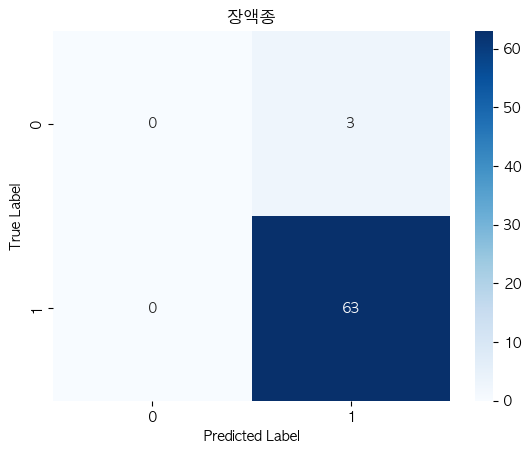

/opt/homebrew/Caskroom/miniforge/base/envs/lipo/lib/python3.8/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/opt/homebrew/Caskroom/miniforge/base/envs/lipo/lib/python3.8/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/opt/homebrew/Caskroom/miniforge/base/envs/lipo/lib/python3.8/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf


               precision    recall  f1-score   support

           0       0.00      0.00      0.00         3
           1       0.95      1.00      0.98        63

    accuracy                           0.95        66
   macro avg       0.48      0.50      0.49        66
weighted avg       0.91      0.95      0.93        66

../dataset/dataset_12v/belly/멍.xlsx
Accuracy with All Features
Train accuracy: 1.00000
Test accuracy: 0.94340


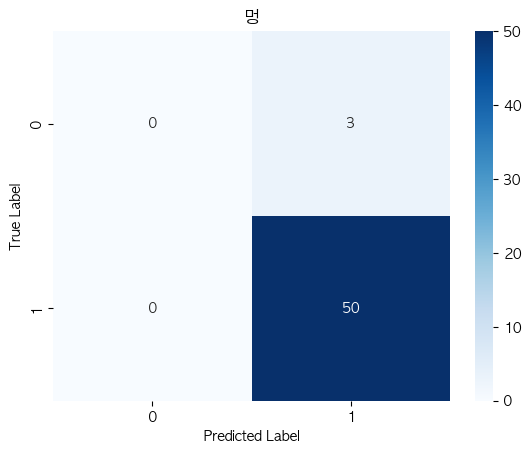


               precision    recall  f1-score   support

           0       0.00      0.00      0.00         3
           1       0.94      1.00      0.97        50

    accuracy                           0.94        53
   macro avg       0.47      0.50      0.49        53
weighted avg       0.89      0.94      0.92        53

../dataset/dataset_12v/belly/뭉침.xlsx


/opt/homebrew/Caskroom/miniforge/base/envs/lipo/lib/python3.8/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/opt/homebrew/Caskroom/miniforge/base/envs/lipo/lib/python3.8/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))
/opt/homebrew/Caskroom/miniforge/base/envs/lipo/lib/python3.8/site-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf

Accuracy with All Features
Train accuracy: 0.93125
Test accuracy: 0.58537


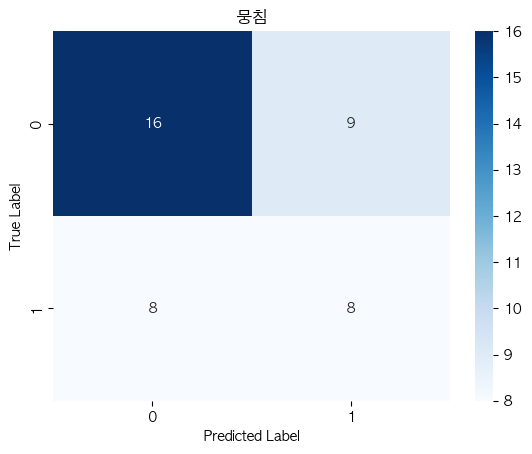


               precision    recall  f1-score   support

           0       0.67      0.64      0.65        25
           1       0.47      0.50      0.48        16

    accuracy                           0.59        41
   macro avg       0.57      0.57      0.57        41
weighted avg       0.59      0.59      0.59        41

../dataset/dataset_12v/belly/울퉁불퉁.xlsx
Accuracy with All Features
Train accuracy: 0.98374
Test accuracy: 0.67742


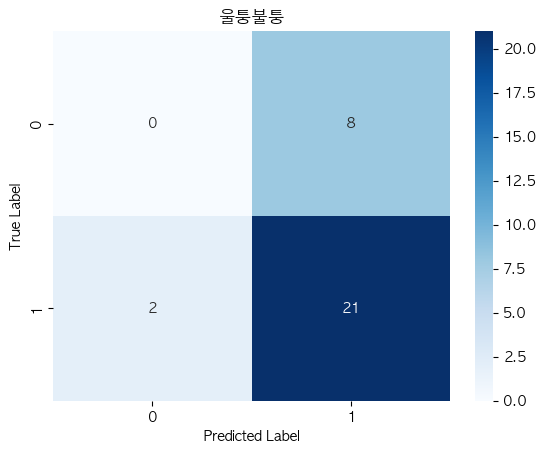


               precision    recall  f1-score   support

           0       0.00      0.00      0.00         8
           1       0.72      0.91      0.81        23

    accuracy                           0.68        31
   macro avg       0.36      0.46      0.40        31
weighted avg       0.54      0.68      0.60        31



In [16]:
for val in aftereffect_list:
    path = data_path + val + sub_path
    print(path)
    data = pd.read_excel(path)
    
    # KPI 데이터만 사용
    # data = data[selected_columns]

    # 8:2 split
    X_train, X_test, y_train, y_test = split_data(data)

    # 테스트셋 저장
    test_data = pd.concat([X_test, y_test], axis=1)
    os.makedirs(save_dir, exist_ok=True)
    test_data.to_excel(os.path.join(save_dir, f'{val}_dataset.xlsx'), index=False)

    # 타겟 클래스를 one-hot 벡터로 변환
    y_train = keras.utils.to_categorical(y_train)
    y_test = keras.utils.to_categorical(y_test)
    
    # 데이터 스케일링
    # data_scaling(X_train, X_test)

    # RandomForestClassifier 모델 객체 생성
    RF_model = RandomForestClassifier(n_estimators=100, random_state=seed)

    # 모든 특징점을 사용하여 모델을 학습시키고, 테스트 데이터에서 성능을 측정
    RF_model.fit(X_train, y_train)

    # 훈련 세트와 검증 세트의 성능 지표 계산
    train_acc = accuracy_score(y_train, RF_model.predict(X_train))
    test_acc = accuracy_score(y_test, RF_model.predict(X_test))

    print("Accuracy with All Features")
    print(f"Train accuracy: {train_acc:.5f}")
    print(f"Test accuracy: {test_acc:.5f}")

    # 모델 저장
    os.makedirs(save_dir, exist_ok=True)
    joblib.dump(RF_model, os.path.join(save_dir, f'{val}_RFmodel.pkl'))
    # RF_model.save(os.path.join(save_dir, '{val}_RFmodel.h5'))
    
    # 검증 세트 예측
    y_pred = RF_model.predict(X_test)

    # 혼동행렬 시각화 및 성능지표 출력
    conf_matrix(y_test, y_pred, val, save_dir)


## Logistic Regression 이용

In [17]:
# for val in aftereffect_list:
#     path = data_path + val + '.csv'
#     print(path)
#     df = pd.read_csv(path)
    
#     # 데이터(input, output)로 사용하지 않는 컬럼 제거
#     data = df.drop(['부위명'], axis=1)

#     # 테스트셋에 사용할 타겟 클래스별 레코드 수 설정
#     min_target = min([count*0.2 for count in data['target'].value_counts()])
#     test_num = int(round(min_target))

#     # 0, 1을 각각 test_num 만큼으로 테스트셋으로 가지도록 트레인셋과 테스트셋으로 split
#     X_train, X_test, y_train, y_test = split_data_ratio(data, test_num, test_num)

#     # 데이터 스케일링
#     data_scaling(X_train, X_test)
    
#     # LogisticRegression 모델 객체 생성
#     LR_model = LogisticRegression(random_state=seed)

#     # 모든 특징점을 사용하여 모델을 학습시키고, 테스트 데이터에서 성능을 측정
#     LR_model.fit(X_train, y_train)

#     # 훈련 세트와 검증 세트의 성능 지표 계산
#     train_acc = LR_model.score(X_train, y_train)
#     test_acc = LR_model.score(X_test, y_test)

#     print("Accuracy with All Features")
#     print(f"Train accuracy: {train_acc:.5f}")
#     print(f"Test accuracy: {test_acc:.5f}")

#     # 검증 세트 예측
#     y_pred = LR_model.predict(X_test)

#     # 혼동행렬 시각화 및 성능지표 출력
#     cm = confusion_matrix(y_test, y_pred)

#     sns.heatmap(cm, annot = True, fmt = 'd',cmap = 'Blues')

#     plt.title(val)
#     plt.xlabel('Predicted Label')
#     plt.ylabel('True Label')

#     plt.savefig(val+'_'+'CMatrix.png')
#     plt.show()

#     print('\n', classification_report(y_test, y_pred))